# 01 LightGBM vs CatBoost vs XGBoost Comparison

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set random state
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load data
df = pd.read_csv('../dataset/pd_speech_features.csv', header=1)
X = df.drop(['id', 'class'], axis=1)
y = df['class']
groups = df['id']

# Print basic stats
print(f"Data shape: {df.shape}")
print(f"Patients: {groups.nunique()}")


Data shape: (756, 755)
Patients: 252


In [2]:
import lightgbm as lgb
import catboost as cb
import xgboost as xgb

models = {
    'XGBoost': xgb.XGBClassifier(tree_method='hist', device='cuda', objective='binary:logistic', eval_metric='logloss', random_state=RANDOM_STATE),
    'LightGBM': lgb.LGBMClassifier(device='gpu', verbose=-1, random_state=RANDOM_STATE),
    'CatBoost': cb.CatBoostClassifier(task_type='GPU', verbose=0, random_state=RANDOM_STATE)
}

results = {}

gkf = GroupKFold(n_splits=5)

for model_name, model in models.items():
    metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
    
    for train_idx, test_idx in gkf.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # Pipeline
        vt = VarianceThreshold(threshold=0.01)
        X_train = vt.fit_transform(X_train)
        X_test = vt.transform(X_test)
        
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        
        skb = SelectKBest(f_classif, k=50)
        X_train = skb.fit_transform(X_train, y_train)
        X_test = skb.transform(X_test)
        
        smote = SMOTE(random_state=RANDOM_STATE)
        X_train, y_train = smote.fit_resample(X_train, y_train)
        
        # Train
        model.fit(X_train, y_train)
        
        # Evaluate
        preds = model.predict(X_test)
        probs = model.predict_proba(X_test)[:, 1]
        
        metrics['acc'].append(accuracy_score(y_test, preds))
        metrics['prec'].append(precision_score(y_test, preds))
        metrics['rec'].append(recall_score(y_test, preds))
        metrics['f1'].append(f1_score(y_test, preds))
        metrics['auc'].append(roc_auc_score(y_test, probs))
        
    results[model_name] = metrics

# Print clean comparison table
print("Model Comparison Results (Mean ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± Std):\n")
print(f"{'Model':<12} | {'Accuracy':<15} | {'Precision':<15} | {'Recall':<15} | {'F1':<15} | {'AUC':<15}")
print("-" * 88)
for model_name in models.keys():
    acc = f"{np.mean(results[model_name]['acc']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[model_name]['acc']):.4f}"
    prec = f"{np.mean(results[model_name]['prec']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[model_name]['prec']):.4f}"
    rec = f"{np.mean(results[model_name]['rec']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[model_name]['rec']):.4f}"
    f1 = f"{np.mean(results[model_name]['f1']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[model_name]['f1']):.4f}"
    auc = f"{np.mean(results[model_name]['auc']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[model_name]['auc']):.4f}"
    print(f"{model_name:<12} | {acc:<15} | {prec:<15} | {rec:<15} | {f1:<15} | {auc:<15}")

# Save results for paper
pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [f"{np.mean(results[m]['acc']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[m]['acc']):.4f}" for m in results],
    'AUC': [f"{np.mean(results[m]['auc']):.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {np.std(results[m]['auc']):.4f}" for m in results]
}).to_csv("boosting_comparison.csv", index=False)


Model Comparison Results (Mean ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± Std):

Model        | Accuracy        | Precision       | Recall          | F1              | AUC            
----------------------------------------------------------------------------------------
XGBoost      | 0.7752 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0396 | 0.8358 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0387 | 0.8731 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0444 | 0.8527 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0256 | 0.7802 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0588
LightGBM     | 0.7632 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0492 | 0.8292 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0375 | 0.8624 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0499 | 0.8444 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0326 | 0.7646 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0794
CatBoost     | 0.7739 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0413 | 0.8424 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0395 | 0.8606 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0490 | 0.8500 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0279 | 0.7964 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0749


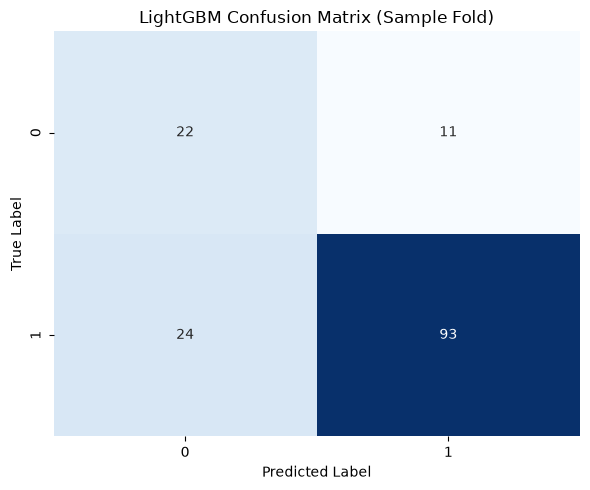

In [3]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Retrain LightGBM on the last fold to get a sample confusion matrix
cm = confusion_matrix(y_test, preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('LightGBM Confusion Matrix (Sample Fold)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('../figures/confusion_matrix_lgb.png', dpi=300)
plt.show()
